# 02 · EDA & Pattern Recognition
Goal: look for relationships between six-month behaviour and next-month default **without assuming they exist**.

Rule used here: anything that will shape our design is measured on the **training split only**. Everything shown is an *observed association*, not a cause.

**Setup.**

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from credit_kg import config as C
import seaborn as sns
from credit_kg import data as D, features as F, stats as S, viz as V

**Load the prepared tables** from notebook 01 and keep the training customers. We also compute the candidate behaviour summaries (averages, counts, slopes) so we can look at them.

In [2]:
wide, monthly, split = D.load_processed()
wide = wide.merge(split)
feats = F.baseline_features(wide)
tr = wide[wide.split == "train"].merge(feats)
y = tr[C.TARGET]
base = y.mean()
print(f"training customers: {len(tr)}, base default rate: {base:.3f}")

training customers: 24000, base default rate: 0.221


**Distributions of money amounts.** Limits, bills and payments are heavily skewed, so we use log scales. Negative bills (credit balances) exist and are shown separately.

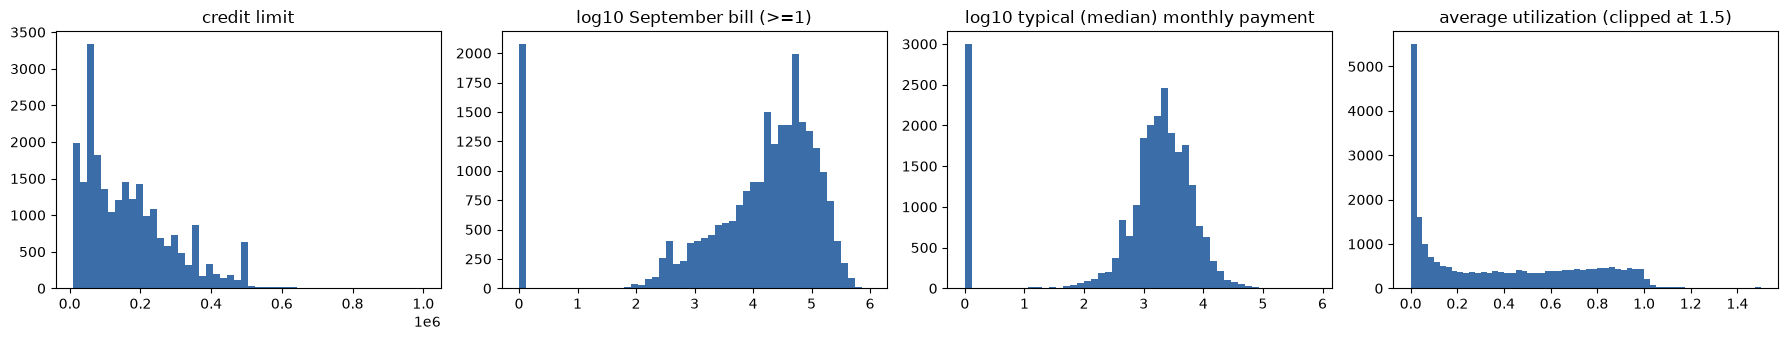

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
ax[0].hist(tr.credit_limit, bins=50, color=V.BASE_COLOR); ax[0].set_title("credit limit")
ax[1].hist(np.log10(tr.bill_m6.clip(lower=1)), bins=50, color=V.BASE_COLOR); ax[1].set_title("log10 September bill (>=1)")
ax[2].hist(np.log10(tr.pay_median.clip(lower=1)), bins=50, color=V.BASE_COLOR); ax[2].set_title("log10 typical (median) monthly payment")
ax[3].hist(tr.util_avg.clip(upper=1.5), bins=60, color=V.BASE_COLOR); ax[3].set_title("average utilization (clipped at 1.5)")
fig.tight_layout(); fig.savefig(C.FIGURES / "eda_distributions.png", dpi=120)

**Unusual groups.** Default rate for customers with odd values. We keep them all, but we need to know whether they behave differently.

In [4]:
groups = {
    "all training customers": pd.Series(True, index=tr.index),
    "any utilization > 100%": (tr[[f"bill_m{m}" for m in C.MONTHS]].max(axis=1) > tr.credit_limit),
    "any negative bill (credit balance)": tr.credit_balance_months > 0,
    "all six bills zero": (tr[[f"bill_m{m}" for m in C.MONTHS]] == 0).all(axis=1),
    "all six payments zero": tr.zero_pay_months == 6,
    "inactive (utilization <= 2% every month)": tr.inactive_flag == 1,
}
odd = pd.DataFrame({k: {"customers": int(m.sum()), "default_rate": round(y[m].mean(), 3)} for k, m in groups.items()}).T
odd.to_csv(C.TABLES / "eda_unusual_groups.csv"); odd

,customers,default_rate
all training customers,24000.0,0.221
any utilization > 100%,3129.0,0.304
any negative bill (credit balance),1553.0,0.157
all six bills zero,699.0,0.365
all six payments zero,1139.0,0.371
inactive (utilization <= 2% every month),3238.0,0.248


**Default rate by the September repayment state.** Note that 'paid in full' (-1) is *not* safer than 'revolving' (0): the negative codes are not ordered by risk.

In [5]:
st = S.default_rate_table(pd.Series(D.status_to_state(tr.status_m6), index=tr.index), y)
st.loc[["NO_USE", "PAID_FULL", "REVOLVING", "LATE_1", "LATE_2PLUS"]]

,n,defaults,default_rate,ci_low,ci_high
bucket,,,,,
NO_USE,2198,279,0.1269,0.1137,0.1415
PAID_FULL,4527,753,0.1663,0.1558,0.1775
REVOLVING,11781,1508,0.1280,0.1221,0.1342
LATE_1,3000,1031,0.3437,0.3269,0.3609
LATE_2PLUS,2494,1738,0.6969,0.6785,0.7146


**Default rate by behaviour bucket.** Each bar is the share of customers in that bucket who defaulted, with a 95% confidence interval; the dashed line is the overall rate.
We look at utilization, payment coverage, delinquency, credit limit, typical payment and the trends.

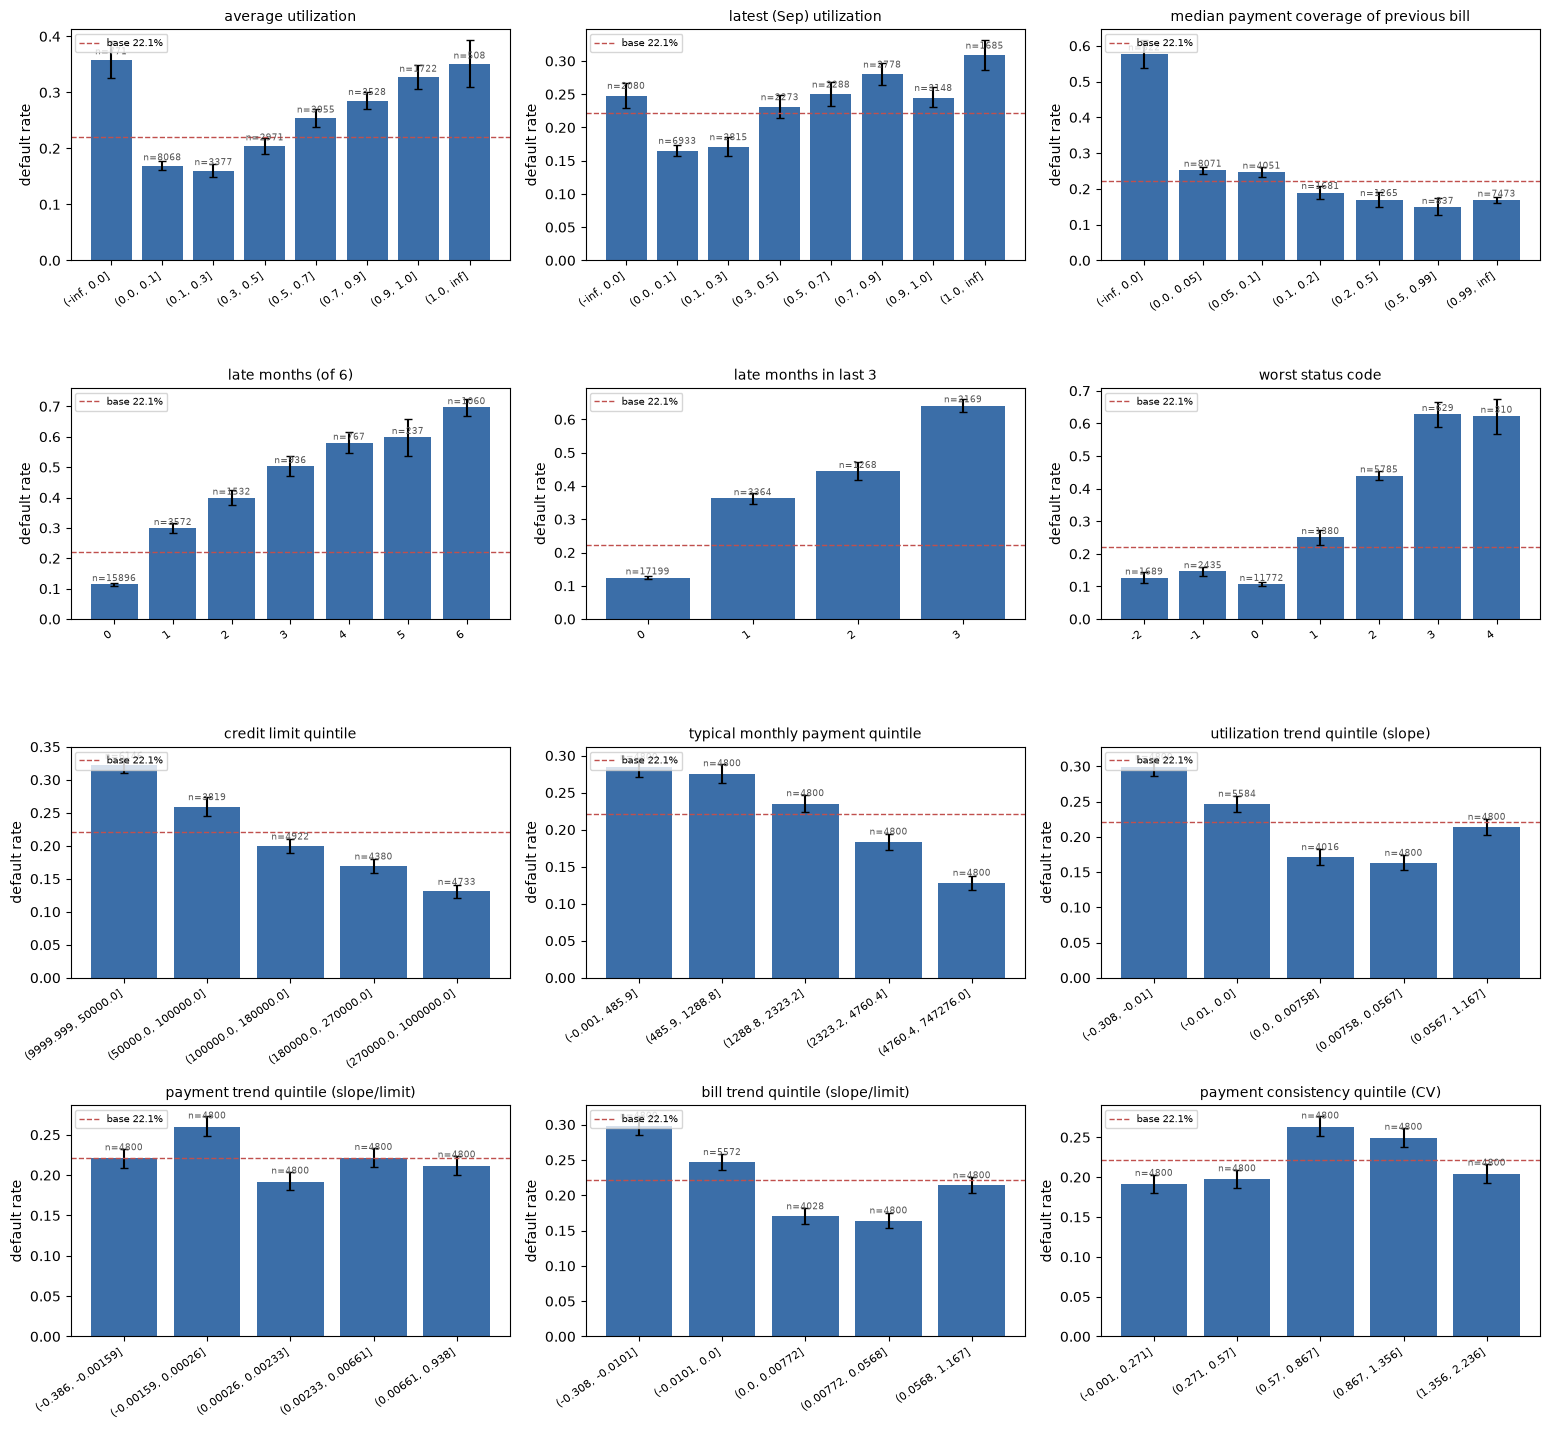

In [6]:
U = [-np.inf, 0, .1, .3, .5, .7, .9, 1.0, np.inf]
tables = {
    "average utilization": S.default_rate_table(tr.util_avg, y, bins=U),
    "latest (Sep) utilization": S.default_rate_table(tr.util_latest, y, bins=U),
    "median payment coverage of previous bill": S.default_rate_table(tr.coverage_median, y, bins=[-np.inf, 0, .05, .1, .2, .5, .99, np.inf]),
    "late months (of 6)": S.default_rate_table(tr.late_months, y),
    "late months in last 3": S.default_rate_table(tr.late_recent3, y),
    "worst status code": S.default_rate_table(tr.max_status.clip(upper=4), y),
    "credit limit quintile": S.default_rate_table(tr.credit_limit, y, q=5),
    "typical monthly payment quintile": S.default_rate_table(tr.pay_median, y, q=5),
    "utilization trend quintile (slope)": S.default_rate_table(tr.util_slope, y, q=5),
    "payment trend quintile (slope/limit)": S.default_rate_table(tr.pay_slope_rel, y, q=5),
    "bill trend quintile (slope/limit)": S.default_rate_table(tr.bill_slope_rel, y, q=5),
    "payment consistency quintile (CV)": S.default_rate_table(tr.pay_cv, y, q=5),
}
V.rate_panel(tables, base, C.FIGURES / "eda_default_rate_buckets.png")
pd.concat(tables, names=["feature"]).to_csv(C.TABLES / "eda_bucket_rates.csv")

**Month-to-month state transitions.** For every pair of consecutive months: if a customer is in state X this month, where are they next month? (Row-normalised; training customers.) This is the population structure the graph will store.

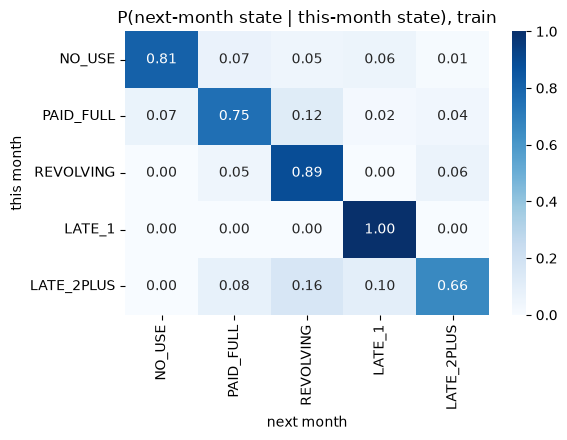

In [7]:
s = D.status_to_state(tr[[f"status_m{m}" for m in C.MONTHS]].to_numpy())
order = ["NO_USE", "PAID_FULL", "REVOLVING", "LATE_1", "LATE_2PLUS"]
trans = pd.crosstab(pd.Series(s[:, :-1].ravel(), name="this month"), pd.Series(s[:, 1:].ravel(), name="next month"), normalize="index")
trans = trans.reindex(index=order, columns=order)
plt.figure(figsize=(6, 4.5)); sns.heatmap(trans, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("P(next-month state | this-month state), train"); plt.tight_layout(); plt.savefig(C.FIGURES / "eda_transition_heatmap.png", dpi=120)

**Monthly trajectories.** Average utilization, share of customers late, and median payment in each month, split by whether the customer later defaulted. This is descriptive only.

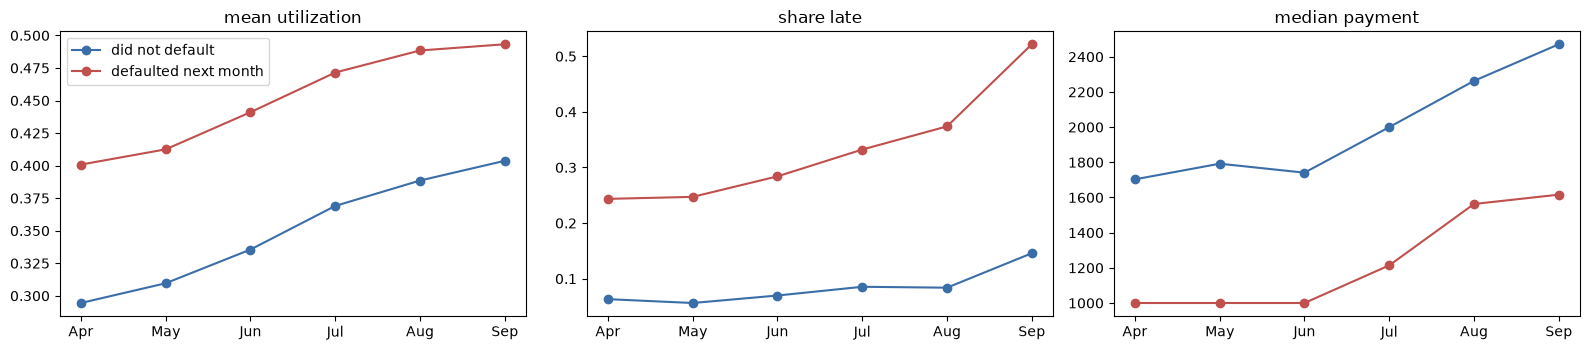

In [8]:
traj = tr.melt(id_vars=[C.TARGET], value_vars=[f"status_m{m}" for m in C.MONTHS])
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
for cls, col in [(0, V.BASE_COLOR), (1, V.REF_COLOR)]:
    sub = tr[tr[C.TARGET] == cls]
    u = np.array([(sub[f"bill_m{m}"].clip(lower=0) / sub.credit_limit).mean() for m in C.MONTHS])
    l = np.array([(sub[f"status_m{m}"] >= 1).mean() for m in C.MONTHS])
    p = np.array([sub[f"pay_m{m}"].median() for m in C.MONTHS])
    lab = "defaulted next month" if cls else "did not default"
    ax[0].plot(list(C.MONTH_NAMES.values()), u, marker="o", color=col, label=lab)
    ax[1].plot(list(C.MONTH_NAMES.values()), l, marker="o", color=col, label=lab)
    ax[2].plot(list(C.MONTH_NAMES.values()), p, marker="o", color=col, label=lab)
ax[0].set_title("mean utilization"); ax[1].set_title("share late"); ax[2].set_title("median payment")
ax[0].legend(); fig.tight_layout(); fig.savefig(C.FIGURES / "eda_monthly_trajectories.png", dpi=120)

**Correlations between candidate features** (Spearman, because amounts are skewed). Very high values mean two features carry almost the same information. We use this in notebook 03 to drop duplicates.

,spearman_with_default
coverage_min,-0.218
credit_limit,-0.178
pay_median,-0.145
coverage_median,-0.129
util_slope,-0.078
bill_slope_rel,-0.078
util_std,-0.026
pay_slope_rel,-0.017
pay_cv,0.024
util_latest,0.078


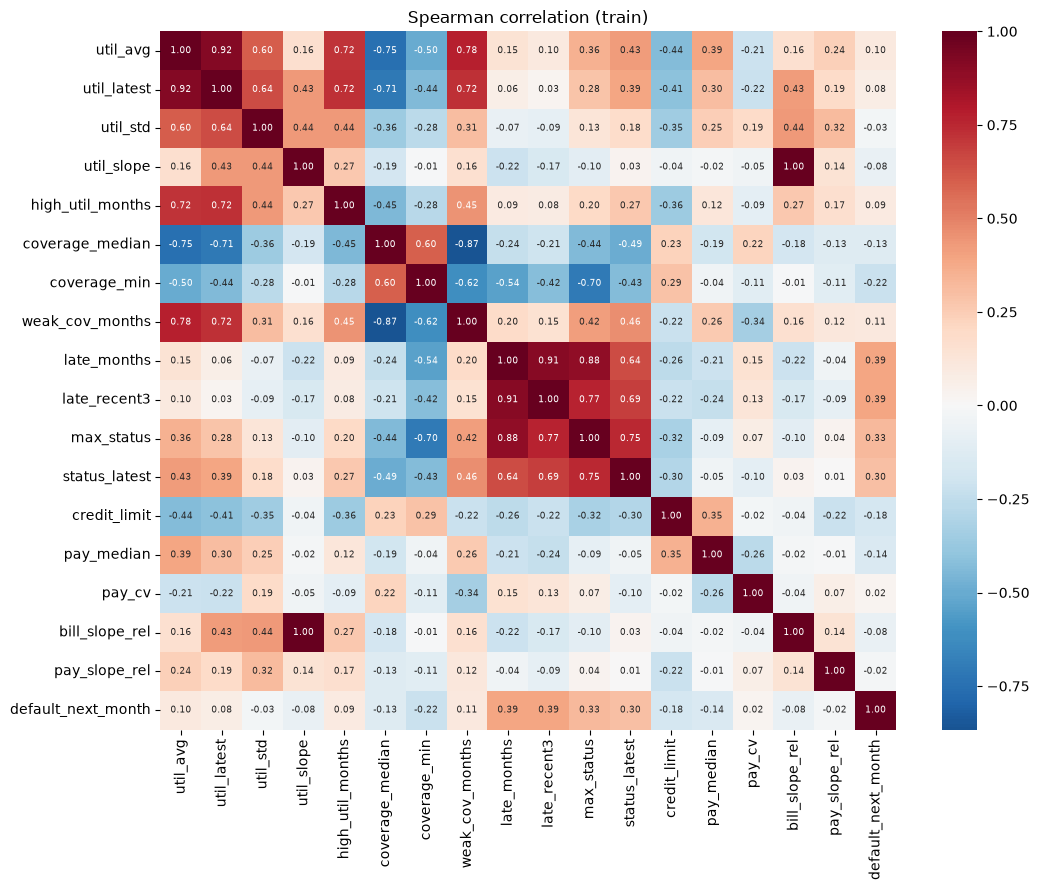

In [9]:
cols = ["util_avg", "util_latest", "util_std", "util_slope", "high_util_months", "coverage_median", "coverage_min",
        "weak_cov_months", "late_months", "late_recent3", "max_status", "status_latest", "credit_limit",
        "pay_median", "pay_cv", "bill_slope_rel", "pay_slope_rel", C.TARGET]
corr = tr[cols].corr(method="spearman")
plt.figure(figsize=(11, 9)); sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 6.5})
plt.title("Spearman correlation (train)"); plt.tight_layout(); plt.savefig(C.FIGURES / "eda_correlation.png", dpi=120)
corr[C.TARGET].drop(C.TARGET).sort_values().round(3).to_frame("spearman_with_default")

**Interaction 1: does *when* you were late matter?** Rows = total late months, columns = late months in the last 3. Same total, but recent lateness shows a higher default rate.

In [10]:
pd.crosstab(tr.late_months, tr.late_recent3, values=y, aggfunc="mean").round(2)

late_recent3,0,1,2,3
late_months,,,,
0,0.12,NaN,NaN,NaN
1,0.21,0.33,NaN,NaN
2,0.30,0.43,0.41,NaN
3,0.31,0.51,0.49,0.57
4,NaN,0.51,0.68,0.59
5,NaN,NaN,0.44,0.62
6,NaN,NaN,NaN,0.70


**Interaction 2: utilization × payment coverage.** High utilization is much riskier when the customer also pays little of the previous bill.

In [11]:
ub = pd.cut(tr.util_avg, [-np.inf, .1, .5, .9, np.inf], labels=["<=10%", "10-50%", "50-90%", ">90%"])
cb = pd.cut(tr.coverage_median, [-np.inf, .1, .5, .99, np.inf], labels=["<10%", "10-50%", "50-99%", "full"])
pd.crosstab(ub, cb, values=y, aggfunc="mean").round(2)

coverage_median,<10%,10-50%,50-99%,full
util_avg,,,,
<=10%,0.33,0.18,0.16,0.17
10-50%,0.20,0.16,0.12,0.11
50-90%,0.27,0.24,0.24,0.11
>90%,0.34,0.22,0.00,0.00


**Interaction 3: credit limit × utilization.**

In [12]:
lb = pd.qcut(tr.credit_limit, 3, labels=["low limit", "mid limit", "high limit"])
pd.crosstab(lb, ub, values=y, aggfunc="mean").round(2)

util_avg,<=10%,10-50%,50-90%,>90%
credit_limit,,,,
low limit,0.27,0.27,0.32,0.36
mid limit,0.20,0.17,0.24,0.29
high limit,0.15,0.08,0.18,0.30


**Demographics (descriptive only).** Shown for completeness. They are *not* used in the credit-increase score, and the main models leave them out.

In [13]:
demo = {c: S.default_rate_table(tr[c], y)[["n", "default_rate"]] for c in ["sex", "education", "marriage"]}
demo["age band"] = S.default_rate_table(tr.age, y, bins=[20, 25, 30, 40, 50, 60, 80])[["n", "default_rate"]]
pd.concat(demo, names=["attribute"])

n  default_rate
attribute bucket                       
sex       1          9486        0.2437
          2         14514        0.2065
education 1          8455        0.1929
          2         11256        0.2376
          3          3903        0.2501
          4           386        0.0725
marriage  1         10892        0.2330
          2         12806        0.2104
          3           302        0.2550
age band  (20, 25]   3104        0.2693
          (25, 30]   5728        0.2018
          (30, 40]   8608        0.2031
          (40, 50]   4762        0.2325
          (50, 60]   1584        0.2544
          (60, 80]    214        0.2757

### What we observed (associations, not causes)
* **Delinquency** is the strongest signal: default rises steadily with the number of late months, and recent lateness matters more than old lateness.
* **Payment coverage** of the previous bill: customers who pay almost nothing of their last statement default far more than those who pay it in full.
* **Credit limit** and **typical payment size**: higher values go with lower default.
* **Utilization is U-shaped**, not a straight line: very low/zero usage *and* very high usage are both riskier than moderate usage.
* **Rising utilization is not riskier**: customers whose utilization *fell* default more often. The expected "deterioration" story is not supported here.
* **Payment trend** and **payment consistency (CV)** show only weak, zig-zag patterns (default rates stay within ~19–26%).
* **Bill trend** looks almost identical to utilization trend (both are bills divided by the limit), so one of them is redundant.
* Customers with *all* bills zero or *all* payments zero default more (~37%), which again says "no activity" is not "safe".
* Repayment codes -2/-1/0 are not ordered by risk.

Notebook 03 checks these formally before any of them becomes a feature or a scoring rule.